# Tutorial 11 — Rheological model fitting

`FitModel` fits constitutive models to small-amplitude oscillatory shear
(SAOS) moduli $G'(\omega)$, $G''(\omega)$ or to a relaxation modulus $G(t)$.
It accepts a single sweep, one temperature of a time–temperature superposition
(TTS) series, or a master curve. Two engines are available:

- the built-in generalized Maxwell (Prony series) model, and
- the classical and fractional models of pyRheo (Miranda-Valdez et al., 2025),
  an optional dependency.

Each fit returns a piblin `Measurement` holding the data, the fitted curves
and, in `details`, the parameters and goodness of fit. The data are a discrete
frequency sweep of a polymer melt at 49 °C.

pyRheo draws random initial guesses from NumPy's global generator, so the
notebook seeds it for reproducible results.

In [1]:
import contextlib
import io
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.transforms.fit_model import FitModel
from hermes_rheo.transforms.frequency_to_time import FrequencyToTime
from hermes_rheo.visualization import use_science_style

use_science_style()
warnings.filterwarnings("ignore")  # pyRheo emits numerical warnings during optimisation
np.random.seed(0)  # pyRheo draws random initial guesses; seed for reproducibility

DATA = Path("tutorial_data")  # run from tutorial_notebooks/

In [2]:
experiment = read_file(
    DATA / "dhr30_trios_owchirp_vs_frequency_sweep.txt",
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)
# Each measurement is one OWChirp spectrum recorded during a temperature ramp;
# pick the one closest to 49 °C.
temperatures = np.array([
    m.datasets[0].data_arrays[m.datasets[0].data_array_names.index("temperature")].mean()
    for m in experiment.measurements
])
sweep = experiment.measurements[int(np.argmin(np.abs(temperatures - 49.0)))]

## SAOS: classical and generalized Maxwell

A Maxwell element, a spring of modulus $G$ in series with a dashpot of
viscosity $\eta$, relaxes with a single time $\tau = \eta/G$:

$$
G'(\omega) = G\,\frac{(\omega\tau)^2}{1 + (\omega\tau)^2},
\qquad
G''(\omega) = G\,\frac{\omega\tau}{1 + (\omega\tau)^2}.
$$

The generalized Maxwell model places $N$ such elements in parallel, giving the
Prony series $G(t) = G_e + \sum_i g_i\, e^{-t/\tau_i}$ and

$$
G'(\omega) = G_e + \sum_{i=1}^{N} g_i\,\frac{(\omega\tau_i)^2}{1 + (\omega\tau_i)^2},
\qquad
G''(\omega) = \sum_{i=1}^{N} g_i\,\frac{\omega\tau_i}{1 + (\omega\tau_i)^2}.
$$

With `mode="nnls"` (default), the $\tau_i$ are fixed on a logarithmic grid
spanning the data and the moduli $g_i \ge 0$ are found by non-negative least
squares, which is fast and needs no initial guesses. The equilibrium modulus
$G_e$ is included with `equilibrium_modulus=True`.

In [3]:
def fit(transform, target):
    """Apply a FitModel transform, silencing the optimiser's progress prints."""
    with contextlib.redirect_stdout(io.StringIO()):
        return transform(target)


fits = {
    "Maxwell": FitModel(model_name="Maxwell"),
    "4-mode Maxwell": FitModel(model="custom", model_name="MultiModeMaxwell", n_modes=4),
}
results = {name: fit(f, sweep) for name, f in fits.items()}
for name, r in results.items():
    print(name, r.details["parameters"])

Maxwell {'G_s': 75030.68610525543, 'eta_s': 13741.92891933592}
4-mode Maxwell {'G_modes': [116393.8358305254, 27882.31360585928, 0.0, 38770.13968926155], 'tau_modes': [0.01591549459100615, 0.07387318085377693, 0.3428889261499121, 1.591549386630056], 'equilibrium_modulus': 0.0}


## SAOS: fractional model

Many soft materials relax as a power law over decades of frequency, which
requires many Maxwell modes. A spring-pot (Scott Blair element) interpolates
between a spring and a dashpot,

$$
\sigma(t) = V\,\frac{\mathrm{d}^{\alpha}\gamma(t)}{\mathrm{d}t^{\alpha}},
\qquad
G^{*}(\omega) = V\,(i\omega)^{\alpha},
\qquad 0 \le \alpha \le 1,
$$

so $\alpha = 0$ is a spring and $\alpha = 1$ a dashpot, and its phase angle
$\delta = \alpha\pi/2$ is independent of frequency. Combining spring-pots
gives compact models with few parameters (Bonfanti et al., 2020; Song et al.,
2023). The fractional Kelvin–Voigt model places two spring-pots in parallel,

$$
G^{*}(\omega) = V\,(i\omega)^{\alpha} + G\,(i\omega)^{\beta},
$$

and captures the two power-law regimes of this sweep with four parameters.
The plot compares the three models: one Maxwell mode cannot describe a broad
spectrum, four modes approximate it with visible ripples, and the fractional
model follows the data closely.

In [4]:
fits["Fractional Kelvin–Voigt"] = FitModel(model_name="FractionalKelvinVoigt")
results["Fractional Kelvin–Voigt"] = fit(fits["Fractional Kelvin–Voigt"], sweep)
print("Fractional Kelvin–Voigt", results["Fractional Kelvin–Voigt"].details["parameters"])

Fractional Kelvin–Voigt {'G': 3178.418976149676, 'V': 42725.90973579788, 'alpha': 0.17453102613238186, 'beta': 0.7293643795406608}


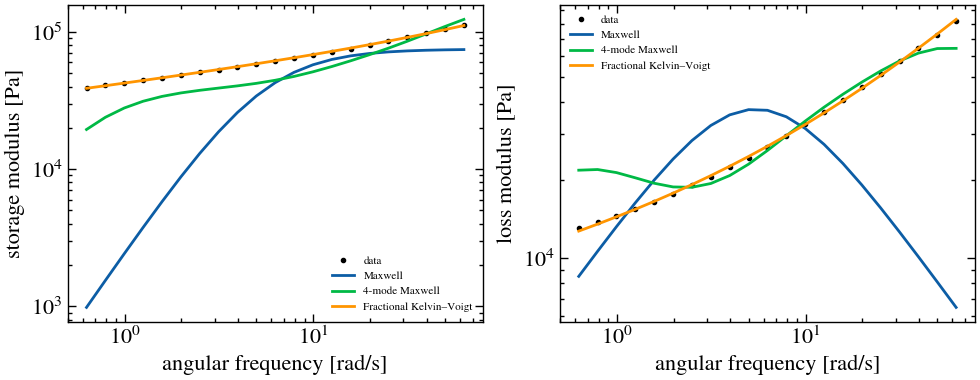

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, y in zip(axes, ("storage modulus", "loss modulus")):
    for i, (name, r) in enumerate(results.items()):
        ds = r.datasets[0]
        arr, unit = dict(zip(ds.data_array_names, ds.data_arrays)), dict(zip(ds.data_array_names, ds.data_array_units))
        x = "angular frequency"
        if i == 0:
            ax.loglog(arr[x], arr[y], "ko", ms=3, label="data")
        ax.loglog(arr[x], arr[f"fitted {y}"], label=name)
    ax.set(xlabel=f"{x} [{unit[x]}]", ylabel=f"{y} [{unit[y]}]")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Relaxation domain

`FrequencyToTime` reconstructs $G(t)$ from the sweep (Tutorial 12), and
`FitModel(domain="relaxation")` fits it directly; the multi-mode Maxwell model
is available only for SAOS data. The fractional Maxwell model places two
spring-pots in series,

$$
G(t) = G\,t^{-\beta}\,E_{\alpha-\beta,\,1-\beta}\!\left(-\frac{G}{V}\,t^{\alpha-\beta}\right),
$$

where $E_{a,b}$ is the two-parameter Mittag-Leffler function. It describes a
power-law decay $G(t) \sim t^{-\beta}$ at short times followed by faster
relaxation at long times. Here `minimization_algorithm="Powell"` gives a more
robust optimum than the default L-BFGS-B.

Fractional Maxwell {'G': 22397.70845533997, 'V': 52045.80882040109, 'alpha': 0.9899999996740758, 'beta': 0.3490522618921849}


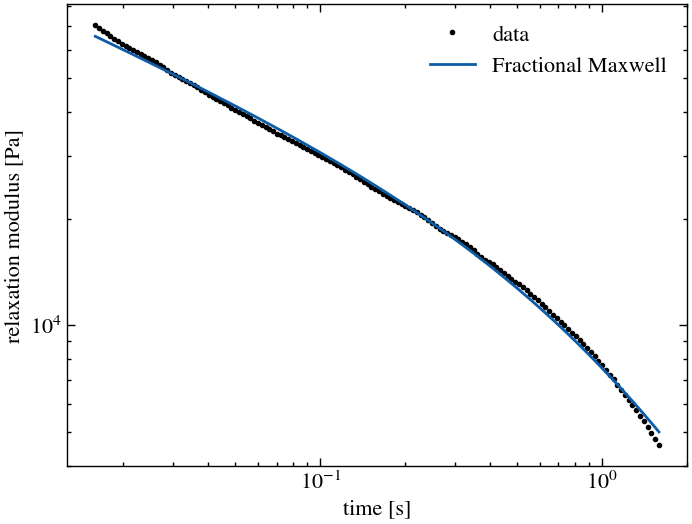

In [6]:
relaxation = FrequencyToTime(n_time_points=150)(sweep)
relax_fit = FitModel(domain="relaxation", model_name="FractionalMaxwell",
                     minimization_algorithm="Powell")
r = fit(relax_fit, relaxation)
print("Fractional Maxwell", r.details["parameters"])

ds = r.datasets[0]
arr, unit = dict(zip(ds.data_array_names, ds.data_arrays)), dict(zip(ds.data_array_names, ds.data_array_units))
plt.loglog(arr["time"], arr["relaxation modulus"], "ko", ms=3, label="data")
plt.loglog(arr["time"], arr["fitted relaxation modulus"], label="Fractional Maxwell")
plt.xlabel(f"time [{unit['time']}]")
plt.ylabel(f"relaxation modulus [{unit['relaxation modulus']}]")
plt.legend(frameon=False)
plt.show()

## References

- Bonfanti, A., Kaplan, J. L., Charras, G. and Kabla, A., *Fractional
  viscoelastic models for power-law materials*, *Soft Matter* **16**,
  6002–6020 (2020). DOI: [10.1039/d0sm00354a](https://doi.org/10.1039/d0sm00354a).
- Song, J., Holten-Andersen, N. and McKinley, G. H., *Non-Maxwellian
  viscoelastic stress relaxations in soft matter*, *Soft Matter* **19**,
  7885–7906 (2023). DOI: [10.1039/d3sm00736g](https://doi.org/10.1039/d3sm00736g).
- Miranda-Valdez, I. Y., Niinistö, J., Mäkinen, T., Lejon, J., Koivisto, J.
  and Alava, M. J., *pyRheo: an open-source Python package for complex
  rheology*, *Digital Discovery* **4**, 1075–1082 (2025).
  DOI: [10.1039/d5dd00021a](https://doi.org/10.1039/d5dd00021a).